# Qwen3 repaired-reconstruction boxplots

Paper-ready grouped boxplots for the seven metrics in the GUI reconstruction table. Each pooling group contains the Qwen3-0.6B-Base, Qwen3-1.7B-Base, and Qwen3-4B-Base decoders.

Every available raw reconstruction is parsed, repaired when necessary, has degenerate component loops collapsed, and is rescored with the repository's shared `repair_rescore.py` / `reconstruction_metrics.py` implementation. Strict and repaired values are never mixed. Incomplete runs are included by default because they are the only currently available observations for some 4B conditions; their sample counts and completion status are printed below.

The final cell exports one vector PDF per metric to `overleaf/graphics/`. Figure dimensions and the other paper-style controls live together in the configuration cell.

In [1]:
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path
import json
import re
import warnings

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from tqdm.auto import tqdm

import repair_rescore

# ------------------------------ Analysis configuration -----------------------
MODEL_SIZES = [0.6, 1.7, 4.0]
MODEL_LABELS = {0.6: "Qwen3 0.6B", 1.7: "Qwen3 1.7B", 4.0: "Qwen3 4B"}
POOL_ORDER = ["4096_last", "4096_avg", "4x4096_avg", "16x4096_avg", "64x4096_avg"]
POOL_LABELS = {
    "4096_last": "4096 last",
    "4096_avg": "4096 avg",
    "4x4096_avg": "4×4096 avg",
    "16x4096_avg": "16×4096 avg",
    "64x4096_avg": "64×4096 avg",
}
RICO_LAYOUT_DIR = Path("../rico-data/data/layouts")
COLLAPSE_LOOPS = True
MAX_WORKERS = None             # None uses all logical CPU cores.
CHUNKSIZE = 8
INCLUDE_INCOMPLETE = True      # Keep partial 4B runs in the plots.
FORCE_RESCORE = False          # True ignores a valid cache and repairs again.
CACHE_PATH = Path("graphics/qwen3_repaired_boxplot_metrics.csv.gz")
CACHE_META_PATH = CACHE_PATH.with_suffix(".meta.json")
CACHE_SCHEMA_VERSION = 1

# -------------------------------- Figure configuration -----------------------
PDF_DIR = Path("overleaf/graphics")
PDF_PREFIX = "qwen3_repaired"
FIGSIZE = (4.75, 2.75)           # inches; change only this for paper sizing.
DPI = 150                      # notebook display only; PDFs remain vector.
SHOW_FLIERS = False            # avoids huge PDFs for ~66k-screen runs.
BOX_WIDTH = 0.72
LINE_WIDTH = 0.8
MIN_BOXPLOT_N = 20             # refuse meaningless one/few-sample boxes.
SHOW_TITLES = False            # captions usually replace titles in LaTeX.
PALETTE = {
    "Qwen3 0.6B": "#4C78A8",
    "Qwen3 1.7B": "#F58518",
    "Qwen3 4B": "#54A24B",
}

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update({
    "figure.dpi": DPI,
    "savefig.dpi": DPI,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

C:\Users\Jonathan\Dev\screen2vec-revisited\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Metrics and Qwen3 experiment discovery

The directory expression intentionally accepts only the five pooling strategies and three Qwen3 Base decoders in the table. It excludes Qwen2.5, Qwen3.5, and the separate non-Base `qwen3-1.7b` artifact.

In [2]:
METRIC_SPECS = {
    "class_accuracy_repaired": {
        "label": "Class accuracy (strict pairing)", "slug": "class_accuracy", "ylim": (0, 1),
    },
    "class_unordered_f1_repaired": {
        "label": "Class accuracy (unordered F1)", "slug": "class_accuracy_unordered", "ylim": (0, 1),
    },
    "class_level_f1_repaired": {
        "label": "Class accuracy (depth-aware F1)", "slug": "class_accuracy_depth_aware", "ylim": (0, 1),
    },
    "levenshtein_similarity_repaired": {
        "label": "Levenshtein similarity", "slug": "levenshtein_similarity", "ylim": (0, 1),
    },
    "levenshtein_distance_repaired": {
        "label": "Levenshtein distance", "slug": "levenshtein_distance", "ylim": None,
    },
    "average_bounds_iou_repaired": {
        "label": "Average bounds IoU", "slug": "average_bounds_iou", "ylim": (0, 1),
    },
    "matched_iou_repaired": {
        "label": "Matched bounds IoU", "slug": "matched_bounds_iou", "ylim": (0, 1),
    },
}

experiment_re = re.compile(
    r"^reconstructions_(?P<pool>4096_(?:last|avg)|(?:4|16|64)x4096_avg)"
    r"__via__embeddings_(?P=pool)_full_qwen3-(?P<size>0\.6|1\.7|4)b-base$"
)

experiment_rows = []
prediction_files = {}

for directory in Path(".").glob("reconstructions_*qwen3-*-base"):
    match = experiment_re.fullmatch(directory.name)
    if match is None:
        continue

    pooling = match.group("pool")
    model_size = float(match.group("size"))
    dim = directory.name.removeprefix("reconstructions_")

    files = {
        path.name.removesuffix("_reconstructed.json"): path
        for path in directory.glob("*_reconstructed.json")
    }

    prediction_files[dim] = files

    experiment_rows.append({
        "dim": dim,
        "pooling": pooling,
        "model_size_b": model_size,
        "model_label": MODEL_LABELS[model_size],
        "directory": directory,
        "directory_path": str(directory.resolve()),
        "n_screens": len(files),
        "latest_mtime_ns": max(
            (p.stat().st_mtime_ns for p in files.values()),
            default=0,
        ),
    })

experiments = pd.DataFrame(experiment_rows)

if experiments.empty:
    raise FileNotFoundError(
        "No Qwen3 Base reconstruction directories were found. "
        "Run from the repository root."
    )

if experiments.duplicated(["pooling", "model_size_b"]).any():
    raise ValueError(
        "More than one directory matched a Qwen3 pooling/model condition."
    )

expected_conditions = {
    (pool, size)
    for pool in POOL_ORDER
    for size in MODEL_SIZES
}

found_conditions = set(
    zip(
        experiments["pooling"],
        experiments["model_size_b"],
    )
)

missing_conditions = expected_conditions - found_conditions

if missing_conditions:
    warnings.warn(
        f"Missing reconstruction directories: {sorted(missing_conditions)}"
    )


def expected_screen_count(row):
    # The table documents the one completed run with a single missing screen.
    if row.pooling == "4x4096_avg" and row.model_size_b == 1.7:
        return 66_260
    return 66_261


experiments["expected_screens"] = [
    expected_screen_count(row)
    for row in experiments.itertuples()
]

experiments["complete"] = (
    experiments["n_screens"]
    >= experiments["expected_screens"]
)

experiments["status"] = experiments["complete"].map({
    True: "complete",
    False: "incomplete (partial)",
})

experiments["pool_order"] = experiments["pooling"].map({
    name: i
    for i, name in enumerate(POOL_ORDER)
})

experiments = experiments.sort_values(
    ["pool_order", "model_size_b"]
).reset_index(drop=True)

run_inventory = experiments[
    [
        "pooling",
        "model_label",
        "directory_path",
        "n_screens",
        "expected_screens",
        "status",
    ]
]

print(run_inventory.to_string(index=False))

    pooling model_label                                                                                                           directory_path  n_screens  expected_screens   status
  4096_last  Qwen3 0.6B     C:\Users\Jonathan\Dev\screen2vec-revisited\reconstructions_4096_last__via__embeddings_4096_last_full_qwen3-0.6b-base      66261             66261 complete
  4096_last  Qwen3 1.7B     C:\Users\Jonathan\Dev\screen2vec-revisited\reconstructions_4096_last__via__embeddings_4096_last_full_qwen3-1.7b-base      66261             66261 complete
  4096_last    Qwen3 4B       C:\Users\Jonathan\Dev\screen2vec-revisited\reconstructions_4096_last__via__embeddings_4096_last_full_qwen3-4b-base      66261             66261 complete
   4096_avg  Qwen3 0.6B       C:\Users\Jonathan\Dev\screen2vec-revisited\reconstructions_4096_avg__via__embeddings_4096_avg_full_qwen3-0.6b-base      66261             66261 complete
   4096_avg  Qwen3 1.7B       C:\Users\Jonathan\Dev\screen2vec-revisited\reconstructi

## Repair and rescore every available prediction

This is deliberately a complete pass (`only_invalid=False` in the older notebook's terminology): valid JSON can still contain repetition loops. Work is grouped by RICO screen so its cleaned ground truth is loaded once and shared across all available Qwen3 conditions.

A compressed cache is reused only when the repair settings and every source directory's file count/latest modification time still match. Set `FORCE_RESCORE=True` above to bypass it.

In [3]:
if not RICO_LAYOUT_DIR.is_dir():
    raise FileNotFoundError(f"RICO layouts not found at {RICO_LAYOUT_DIR.resolve()}")

inventory_signature = {
    row.dim: {"count": int(row.n_screens), "latest_mtime_ns": int(row.latest_mtime_ns)}
    for row in experiments.itertuples(index=False)
}
wanted_metadata = {
    "schema_version": CACHE_SCHEMA_VERSION,
    "collapse_loops": COLLAPSE_LOOPS,
    "inventory": inventory_signature,
}

cache_is_current = False
if not FORCE_RESCORE and CACHE_PATH.is_file() and CACHE_META_PATH.is_file():
    try:
        cache_is_current = json.loads(CACHE_META_PATH.read_text(encoding="utf-8")) == wanted_metadata
    except (OSError, json.JSONDecodeError):
        cache_is_current = False

if cache_is_current:
    repaired = pd.read_csv(CACHE_PATH, dtype={"dim": str, "idx": str})
    print(f"Loaded {len(repaired):,} repaired rows from {CACHE_PATH}")
else:
    all_screen_ids = sorted(
        set().union(*(set(files) for files in prediction_files.values())), key=int
    )
    tasks = []
    for screen_id in all_screen_ids:
        entries = [
            (dim, str(files[screen_id]))
            for dim, files in prediction_files.items()
            if screen_id in files
        ]
        tasks.append((screen_id, str(RICO_LAYOUT_DIR / f"{screen_id}.json"), entries))

    n_predictions = sum(len(task[2]) for task in tasks)
    print(f"Repairing and rescoring {n_predictions:,} predictions across {len(tasks):,} screens")
    repaired_rows = []
    with ProcessPoolExecutor(
        max_workers=MAX_WORKERS,
        initializer=repair_rescore.init_worker,
        initargs=(COLLAPSE_LOOPS,),
    ) as pool:
        for screen_rows in tqdm(
            pool.map(repair_rescore.rescore_item, tasks, chunksize=CHUNKSIZE),
            total=len(tasks), desc="repair + rescore",
        ):
            repaired_rows.extend(screen_rows)

    repaired = pd.DataFrame(repaired_rows)
    if "rescore_error" in repaired.columns:
        failures = repaired[repaired["rescore_error"].notna()]
        if not failures.empty:
            raise RuntimeError(f"{len(failures)} predictions could not be rescored:\n{failures.head()}")
    repaired["idx"] = repaired["idx"].astype(str)
    keep_columns = [
        "dim", "idx", "json_valid_repaired", "json_repair_used", "components_collapsed",
        *METRIC_SPECS.keys(),
    ]
    repaired = repaired[keep_columns]
    CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    repaired.to_csv(CACHE_PATH, index=False, compression="gzip")
    CACHE_META_PATH.write_text(json.dumps(wanted_metadata, indent=2), encoding="utf-8")
    print(f"Cached {len(repaired):,} repaired rows at {CACHE_PATH}")

expected_rows = int(experiments["n_screens"].sum())
if len(repaired) != expected_rows:
    raise AssertionError(f"Expected {expected_rows:,} rows, found {len(repaired):,}")

Repairing and rescoring 993,914 predictions across 66,261 screens


repair + rescore: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 66261/66261 [16:42<00:00, 66.13it/s]


Cached 993,914 repaired rows at graphics\qwen3_repaired_boxplot_metrics.csv.gz


## Descriptive statistics

The printed table reports the requested per-condition mean, sample SD, median, and IQR (`Q3 − Q1`), plus `n`. The CSV export preserves full precision.

In [4]:
analysis = repaired.merge(
    experiments[["dim", "pooling", "model_size_b", "model_label", "complete", "status"]],
    on="dim", how="left", validate="many_to_one",
)
if analysis["pooling"].isna().any():
    raise AssertionError("Cached rows contain an unrecognized experiment directory.")
for metric in METRIC_SPECS:
    analysis[metric] = pd.to_numeric(analysis[metric], errors="coerce")
if analysis[list(METRIC_SPECS)].isna().any().any():
    missing = analysis[list(METRIC_SPECS)].isna().sum()
    raise AssertionError(f"Missing repaired metric values:\n{missing[missing.gt(0)]}")

analysis["pooling_label"] = pd.Categorical(
    analysis["pooling"].map(POOL_LABELS),
    categories=[POOL_LABELS[name] for name in POOL_ORDER], ordered=True,
)
analysis["model_label"] = pd.Categorical(
    analysis["model_label"],
    categories=[MODEL_LABELS[size] for size in MODEL_SIZES], ordered=True,
)
plot_data = analysis if INCLUDE_INCOMPLETE else analysis[analysis["complete"]].copy()

long_metrics = analysis.melt(
    id_vars=["pooling", "model_size_b", "model_label", "status"],
    value_vars=list(METRIC_SPECS), var_name="metric", value_name="value",
)
descriptive = (
    long_metrics.groupby(
        ["pooling", "model_size_b", "model_label", "status", "metric"],
        observed=True, as_index=False,
    )["value"]
    .agg(
        n="count", mean="mean", sd="std", median="median",
        q1=lambda values: values.quantile(0.25),
        q3=lambda values: values.quantile(0.75),
    )
)
descriptive["iqr"] = descriptive["q3"] - descriptive["q1"]
descriptive["pool_order"] = descriptive["pooling"].map({name: i for i, name in enumerate(POOL_ORDER)})
descriptive = descriptive.sort_values(["metric", "pool_order", "model_size_b"]).drop(columns="pool_order")

PDF_DIR.mkdir(parents=True, exist_ok=True)
stats_path = PDF_DIR / f"{PDF_PREFIX}_descriptive_statistics.csv"
descriptive.to_csv(stats_path, index=False)
for metric, spec in METRIC_SPECS.items():
    print(f"\n{spec['label']}")
    table = descriptive.loc[
        descriptive["metric"].eq(metric),
        ["pooling", "model_label", "status", "n", "mean", "sd", "median", "iqr"],
    ]
    print(table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
print(f"\nExported full-precision statistics to {stats_path}")


Class accuracy (strict pairing)
    pooling model_label   status     n   mean     sd  median    iqr
  4096_last  Qwen3 0.6B complete 66261 0.2848 0.3165  0.1875 0.4500
  4096_last  Qwen3 1.7B complete 66261 0.2747 0.3254  0.1500 0.4545
  4096_last    Qwen3 4B complete 66261 0.2790 0.3128  0.1765 0.4444
   4096_avg  Qwen3 0.6B complete 66261 0.2120 0.2800  0.1053 0.3095
   4096_avg  Qwen3 1.7B complete 66261 0.2718 0.3008  0.1818 0.4167
   4096_avg    Qwen3 4B complete 66261 0.1230 0.2330  0.0000 0.1429
 4x4096_avg  Qwen3 0.6B complete 66261 0.3411 0.3289  0.2500 0.4916
 4x4096_avg  Qwen3 1.7B complete 66260 0.3520 0.3251  0.2745 0.4760
 4x4096_avg    Qwen3 4B complete 66261 0.2399 0.2878  0.1429 0.3600
16x4096_avg  Qwen3 0.6B complete 66261 0.3857 0.3311  0.3200 0.5000
16x4096_avg  Qwen3 1.7B complete 66261 0.3808 0.3329  0.3077 0.5062
16x4096_avg    Qwen3 4B complete 66261 0.3155 0.3160  0.2222 0.4524
64x4096_avg  Qwen3 0.6B complete 66261 0.3705 0.3296  0.2917 0.4881
64x4096_avg  Qw

## Seaborn grouped boxplots and PDF export

Boxes use the standard Tukey definition (quartiles with 1.5×IQR whiskers). Outlier markers are hidden by default to keep the vector PDFs compact; this does not change any box or whisker statistic.

Exported overleaf\graphics\qwen3_repaired_class_accuracy_boxplot.pdf


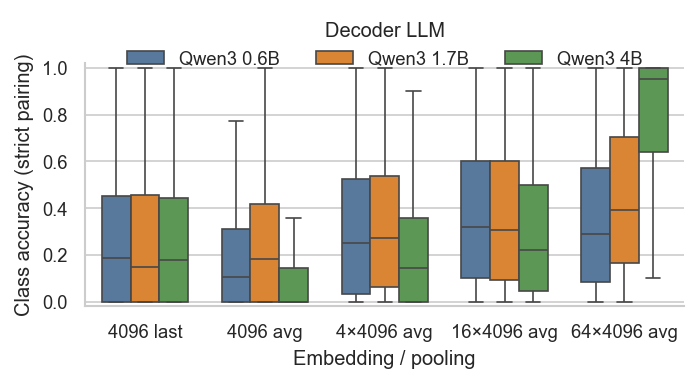

Exported overleaf\graphics\qwen3_repaired_class_accuracy_unordered_boxplot.pdf


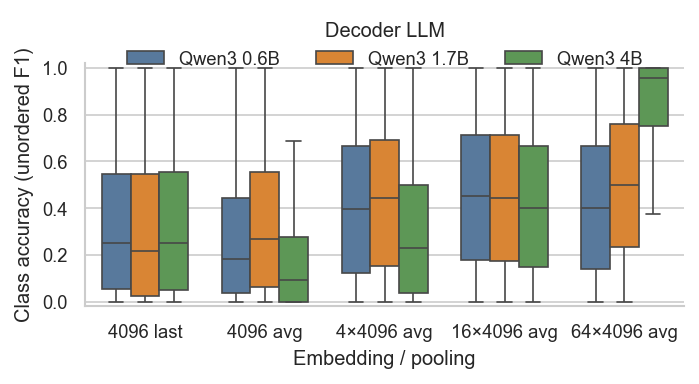

Exported overleaf\graphics\qwen3_repaired_class_accuracy_depth_aware_boxplot.pdf


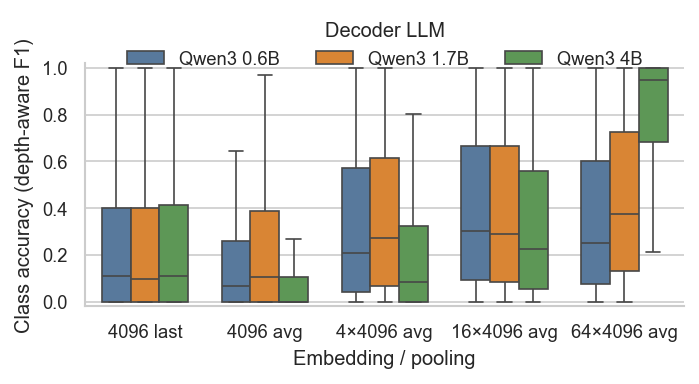

Exported overleaf\graphics\qwen3_repaired_levenshtein_similarity_boxplot.pdf


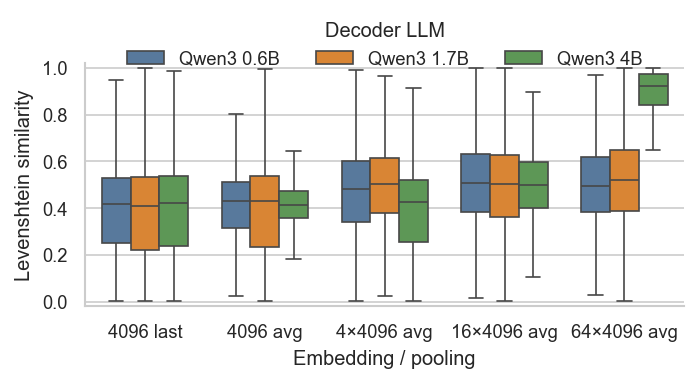

Exported overleaf\graphics\qwen3_repaired_levenshtein_distance_boxplot.pdf


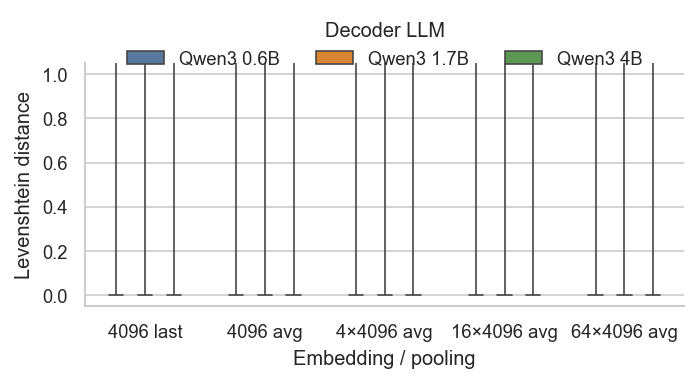

Exported overleaf\graphics\qwen3_repaired_average_bounds_iou_boxplot.pdf


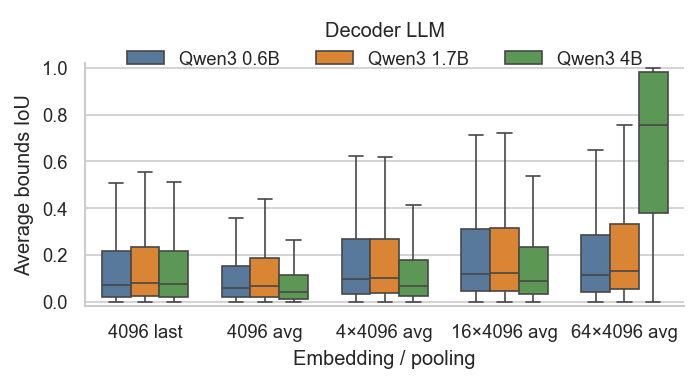

Exported overleaf\graphics\qwen3_repaired_matched_bounds_iou_boxplot.pdf


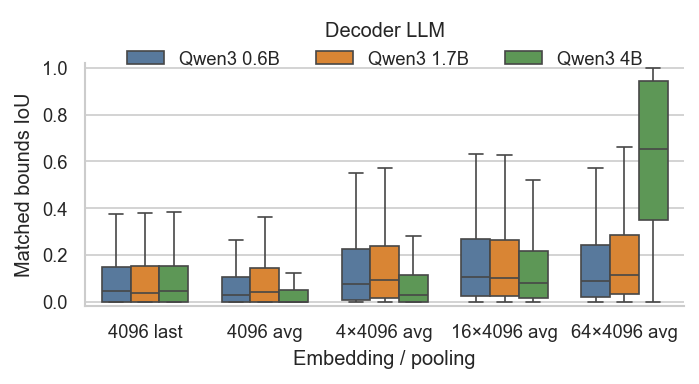


PDF exports:
overleaf\graphics\qwen3_repaired_class_accuracy_boxplot.pdf
overleaf\graphics\qwen3_repaired_class_accuracy_unordered_boxplot.pdf
overleaf\graphics\qwen3_repaired_class_accuracy_depth_aware_boxplot.pdf
overleaf\graphics\qwen3_repaired_levenshtein_similarity_boxplot.pdf
overleaf\graphics\qwen3_repaired_levenshtein_distance_boxplot.pdf
overleaf\graphics\qwen3_repaired_average_bounds_iou_boxplot.pdf
overleaf\graphics\qwen3_repaired_matched_bounds_iou_boxplot.pdf


In [5]:
plot_group_counts = plot_data.groupby(["pooling", "model_label"], observed=True).size()
too_small = plot_group_counts[plot_group_counts.lt(MIN_BOXPLOT_N)]
if not too_small.empty:
    raise ValueError(
        f"Refusing to export boxplots with fewer than {MIN_BOXPLOT_N} observations:\n{too_small}"
    )

Y_PADDING_FRACTION = 0.02


def grouped_boxplot(metric, spec):
    fig, ax = plt.subplots(figsize=FIGSIZE)

    sns.boxplot(
        data=plot_data,
        x="pooling_label",
        y=metric,
        hue="model_label",
        order=[POOL_LABELS[name] for name in POOL_ORDER],
        hue_order=[MODEL_LABELS[size] for size in MODEL_SIZES],
        palette=PALETTE,
        width=BOX_WIDTH,
        linewidth=LINE_WIDTH,
        showfliers=SHOW_FLIERS,
        whis=1.5,
        ax=ax,
    )
    
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("Embedding / pooling")
    ax.set_ylabel(spec["label"])

    if spec["ylim"] is not None:
        y_min, y_max = spec["ylim"]

        # First use the intended metric range to obtain sensible tick positions.
        ax.set_ylim(y_min, y_max)
        y_ticks = ax.get_yticks()
        y_ticks = y_ticks[(y_ticks >= y_min) & (y_ticks <= y_max)]

        # Add a very small visual margin above and below the metric range.
        y_range = y_max - y_min
        y_pad = Y_PADDING_FRACTION * y_range

        ax.set_ylim(
            y_min - y_pad,
            y_max + y_pad,
        )

        # Keep tick labels restricted to the actual metric range.
        ax.set_yticks(y_ticks)

    if SHOW_TITLES:
        ax.set_title(f"{spec['label']} — repaired reconstructions")

    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="x", visible=False)

    legend = ax.legend(
        title="Decoder LLM",
        loc="upper center",
        bbox_to_anchor=(0.5, 1.20),
        ncol=3,
        frameon=False,
        borderaxespad=0,
    )

    fig.tight_layout()

    output_path = PDF_DIR / f"{PDF_PREFIX}_{spec['slug']}_boxplot.pdf"

    fig.savefig(
        output_path,
        format="pdf",
        bbox_inches="tight",
        metadata={
            "Creator": "Matplotlib + Seaborn",
            "Title": spec["label"],
        },
    )

    print(f"Exported {output_path}")

    return fig, ax, output_path


exported_pdfs = []

for metric, spec in METRIC_SPECS.items():
    fig, ax, output_path = grouped_boxplot(metric, spec)
    exported_pdfs.append(output_path)

    plt.show()
    plt.close(fig)

print("\nPDF exports:")
print("\n".join(str(path) for path in exported_pdfs))

In [6]:
# Generate every table entry from the descriptive statistics computed above.
import math

TABLE_METRICS = [
    "class_accuracy_repaired", "class_unordered_f1_repaired",
    "class_level_f1_repaired", "levenshtein_similarity_repaired",
    "levenshtein_distance_repaired", "average_bounds_iou_repaired",
    "matched_iou_repaired",
]
table_stats = descriptive.set_index(
    ["pooling", "model_size_b", "metric"], verify_integrity=True
)

table_header = r"""\begin{table*}[t]
    \centering
    \caption{GUI reconstruction performance across embedding pooling strategies and decoder LLMs after JSON repair and repetition-loop collapse.
    For each metric, we report the per-screen mean and sample standard deviation (SD).
    Class Accuracy (strict) uses strict component pairing; Class Accuracy (unordered) and Class Accuracy (depth-aware) are the respective F1 scores.}
    \label{tab:gui_reconstruction_results}
    \scriptsize
    \begingroup
    \setlength{\tabcolsep}{2.2pt}
    \renewcommand{\arraystretch}{1.1}
    \resizebox{\linewidth}{!}{%
    \begin{tabular}{@{}ll|*{7}{rr}@{}}
        \toprule
        \textbf{Embedding/Pooling} &
        \textbf{Decoder LLM} &
        \multicolumn{2}{|c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(strict)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(unordered)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(depth-aware)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Levenshtein}\\\textbf{Similarity}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Levenshtein}\\\textbf{Distance}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Average Bounds}\\\textbf{IoU}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Matched Bounds}\\\textbf{IoU}}} \\
        \cmidrule(lr){3-4}
        \cmidrule(lr){5-6}
        \cmidrule(lr){7-8}
        \cmidrule(lr){9-10}
        \cmidrule(lr){11-12}
        \cmidrule(lr){13-14}
        \cmidrule(lr){15-16}
        &
        &
        \multicolumn{1}{|c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} \\
"""

table_rows = []
for pooling in POOL_ORDER:
    table_rows.append(r"        \midrule")
    pooling_tex = pooling.replace("_", r"\_")
    table_rows.append(
        r"        \multirow{" + str(len(MODEL_SIZES))
        + r"}{*}{\texttt{" + pooling_tex + "}}"
    )
    for model_size in MODEL_SIZES:
        table_rows.append(f"            & Qwen3-{model_size:g}B-Base")
        for metric in TABLE_METRICS:
            stats = table_stats.loc[(pooling, model_size, metric)]
            mean, sd = float(stats["mean"]), float(stats["sd"])
            if not all(math.isfinite(value) for value in (mean, sd)):
                raise ValueError(f"Missing mean/SD for {pooling}, {model_size}B, {metric}")
            digits = 2 if metric == "levenshtein_distance_repaired" else 4
            table_rows.append(f"            & {mean:.{digits}f} & {sd:.{digits}f}")
        table_rows[-1] += r" \\"

table_footer = r"""        \bottomrule
    \end{tabular}%
    }
    \endgroup
\end{table*}"""

latex_table = table_header + "\n".join(table_rows) + "\n" + table_footer
print(latex_table)

C:\Users\Jonathan\AppData\Local\Temp\ipykernel_28736\1600599013.py:10: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  table_stats = descriptive.set_index(


\begin{table*}[t]
    \centering
    \caption{GUI reconstruction performance across embedding pooling strategies and decoder LLMs after JSON repair and repetition-loop collapse.
    For each metric, we report the per-screen mean and sample standard deviation (SD).
    Class Accuracy (strict) uses strict component pairing; Class Accuracy (unordered) and Class Accuracy (depth-aware) are the respective F1 scores.}
    \label{tab:gui_reconstruction_results}
    \scriptsize
    \begingroup
    \setlength{\tabcolsep}{2.2pt}
    \renewcommand{\arraystretch}{1.1}
    \resizebox{\linewidth}{!}{%
    \begin{tabular}{@{}ll|*{7}{rr}@{}}
        \toprule
        \textbf{Embedding/Pooling} &
        \textbf{Decoder LLM} &
        \multicolumn{2}{|c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(strict)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(unordered)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(depth-aware)}}} &
        \multic

## Validation-only analysis

The cells below reproduce the adapter trainer's held-out validation membership and then select those screen IDs from the repaired metrics already loaded above. They do **not** load model weights, train an adapter, generate JSON, or rescore a reconstruction. The tokenizer is used only to reproduce the historical 4,096-token target-length exclusion that happened before the ordered 80/20 split.

The recovered split is cached with its inputs and code hashes. Complete conditions should contribute 13,192 validation screens; partial reconstruction runs contribute the intersection of their available predictions with that same held-out set.

In [7]:
# Recover the exact ordered split used by 2_train_adapter.py. This is token
# counting only: no decoder weights or reconstruction code are loaded.
import hashlib
from itertools import repeat

from transformers import AutoTokenizer
from utils import process_json_file

VALIDATION_TOKENIZER_ID = "Qwen/Qwen3-1.7B-Base"
VALIDATION_MAX_TARGET_LEN = 4096
VALIDATION_WORLD_SIZE = 8
VALIDATION_SPLIT_CACHE = Path("graphics/qwen3_adapter_validation_ids.csv.gz")
VALIDATION_SPLIT_META = Path("graphics/qwen3_adapter_validation_ids.meta.json")
VALIDATION_SPLIT_SCHEMA = 1


def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def numeric_embedding_ids(directory):
    paths = Path(directory).glob("*.npz")
    return sorted(int(path.stem) for path in paths)


embedding_ids_by_pool = {
    pooling: numeric_embedding_ids(f"embeddings_{pooling}")
    for pooling in POOL_ORDER
}
reference_ids = embedding_ids_by_pool[POOL_ORDER[0]]
reference_id_set = set(reference_ids)
for pooling, ids in embedding_ids_by_pool.items():
    if set(ids) != reference_id_set:
        raise AssertionError(
            f"embeddings_{pooling} does not contain the same screen IDs as "
            f"embeddings_{POOL_ORDER[0]}; a shared validation split is unsafe."
        )

id_digest = hashlib.sha256(
    ",".join(map(str, reference_ids)).encode("ascii")
).hexdigest()
split_inputs = {
    "schema_version": VALIDATION_SPLIT_SCHEMA,
    "tokenizer_id": VALIDATION_TOKENIZER_ID,
    "max_target_len": VALIDATION_MAX_TARGET_LEN,
    "world_size": VALIDATION_WORLD_SIZE,
    "embedding_id_count": len(reference_ids),
    "embedding_id_sha256": id_digest,
    "utils_sha256": sha256_file("utils.py"),
    "trainer_sha256": sha256_file("2_train_adapter.py"),
}

split_cache_current = False
if VALIDATION_SPLIT_CACHE.is_file() and VALIDATION_SPLIT_META.is_file():
    try:
        saved_split_meta = json.loads(VALIDATION_SPLIT_META.read_text(encoding="utf-8"))
        split_cache_current = saved_split_meta.get("inputs") == split_inputs
    except (OSError, json.JSONDecodeError):
        split_cache_current = False

if split_cache_current:
    split_manifest = pd.read_csv(VALIDATION_SPLIT_CACHE, dtype={"idx": int, "split": str})
    split_results = saved_split_meta["results"]
    print(f"Loaded cached adapter split from {VALIDATION_SPLIT_CACHE}")
else:
    tokenizer = AutoTokenizer.from_pretrained(VALIDATION_TOKENIZER_ID, use_fast=True)
    split_rows = []
    candidate_ids = []
    candidate_targets = []
    json_paths = [str(RICO_LAYOUT_DIR / f"{screen_id}.json") for screen_id in reference_ids]

    # process_json_file is defined in the importable utils module, so this
    # remains compatible with Windows ProcessPoolExecutor workers.
    with ProcessPoolExecutor(max_workers=MAX_WORKERS) as pool:
        target_iterator = pool.map(
            process_json_file, json_paths, repeat(True), chunksize=CHUNKSIZE
        )
        target_iterator = tqdm(
            target_iterator, total=len(reference_ids),
            desc="Cleaning targets for split recovery",
        )
        for screen_id, target_json in zip(reference_ids, target_iterator):
            if not target_json or len(target_json) < 5:
                split_rows.append({"idx": screen_id, "split": "excluded_unusable", "target_tokens": pd.NA})
            elif len(target_json) + 1 <= VALIDATION_MAX_TARGET_LEN:
                candidate_ids.append(screen_id)
                candidate_targets.append(None)
            else:
                candidate_ids.append(screen_id)
                candidate_targets.append(target_json)

    target_token_counts = {}
    long_positions = [i for i, target in enumerate(candidate_targets) if target is not None]
    token_batch_size = 128
    for start in tqdm(range(0, len(long_positions), token_batch_size), desc="Counting long target tokens"):
        positions = long_positions[start:start + token_batch_size]
        encoded = tokenizer(
            [candidate_targets[i] for i in positions],
            add_special_tokens=False, truncation=False, padding=False,
            return_length=True,
        )
        for position, length in zip(positions, encoded["length"]):
            target_token_counts[candidate_ids[position]] = int(length) + 1  # EOS

    eligible_ids = []
    for screen_id, target_json in zip(candidate_ids, candidate_targets):
        n_tokens = target_token_counts.get(screen_id)
        if n_tokens is not None and n_tokens > VALIDATION_MAX_TARGET_LEN:
            split_rows.append({"idx": screen_id, "split": "excluded_too_long", "target_tokens": n_tokens})
        else:
            eligible_ids.append(screen_id)

    train_size = int(len(eligible_ids) * 0.8)
    train_before_shard = eligible_ids[:train_size]
    validation_before_shard = eligible_ids[train_size:]
    train_usable = (len(train_before_shard) // VALIDATION_WORLD_SIZE) * VALIDATION_WORLD_SIZE
    validation_usable = (len(validation_before_shard) // VALIDATION_WORLD_SIZE) * VALIDATION_WORLD_SIZE

    train_ids = train_before_shard[:train_usable]
    train_tail_ids = train_before_shard[train_usable:]
    validation_ids = validation_before_shard[:validation_usable]
    validation_tail_ids = validation_before_shard[validation_usable:]

    split_rows.extend({"idx": idx, "split": "train", "target_tokens": pd.NA} for idx in train_ids)
    split_rows.extend({"idx": idx, "split": "excluded_train_shard_tail", "target_tokens": pd.NA} for idx in train_tail_ids)
    split_rows.extend({"idx": idx, "split": "validation", "target_tokens": pd.NA} for idx in validation_ids)
    split_rows.extend({"idx": idx, "split": "excluded_validation_shard_tail", "target_tokens": pd.NA} for idx in validation_tail_ids)

    split_manifest = pd.DataFrame(split_rows).sort_values("idx").reset_index(drop=True)
    if len(split_manifest) != len(reference_ids) or split_manifest["idx"].duplicated().any():
        raise AssertionError("Recovered split does not assign every embedding ID exactly once.")

    split_counts = split_manifest["split"].value_counts().to_dict()
    split_results = {
        "counts": {name: int(count) for name, count in split_counts.items()},
        "train_shard_tail_ids": train_tail_ids,
        "validation_shard_tail_ids": validation_tail_ids,
        "tokenizer_commit_hash": tokenizer.init_kwargs.get("_commit_hash"),
    }
    VALIDATION_SPLIT_CACHE.parent.mkdir(parents=True, exist_ok=True)
    split_manifest.to_csv(VALIDATION_SPLIT_CACHE, index=False, compression="gzip")
    VALIDATION_SPLIT_META.write_text(
        json.dumps({"inputs": split_inputs, "results": split_results}, indent=2),
        encoding="utf-8",
    )
    print(f"Cached recovered adapter split at {VALIDATION_SPLIT_CACHE}")

validation_ids = set(
    split_manifest.loc[split_manifest["split"].eq("validation"), "idx"].astype(int)
)
train_ids = set(split_manifest.loc[split_manifest["split"].eq("train"), "idx"].astype(int))
if train_ids & validation_ids:
    raise AssertionError("Training and validation IDs overlap.")
if not validation_ids:
    raise AssertionError("Recovered validation set is empty.")

display(split_manifest["split"].value_counts().rename_axis("membership").to_frame("n"))
print(f"Validation IDs: {len(validation_ids):,}")
print(f"Validation shard-tail exclusions: {split_results['validation_shard_tail_ids']}")

Loaded cached adapter split from graphics\qwen3_adapter_validation_ids.csv.gz


,n
membership,
train,52776
validation,13192
excluded_too_long,290
excluded_validation_shard_tail,3


Validation IDs: 13,192
Validation shard-tail exclusions: [72216, 72217, 72218]


## Validation-only descriptive statistics

These statistics use only the held-out validation IDs that contributed no adapter-training gradients. For incomplete reconstruction conditions, `n` is the number of those validation IDs for which a reconstruction is available.

In [8]:
validation_analysis = analysis[
    analysis["idx"].astype(int).isin(validation_ids)
].copy()
validation_available = (
    validation_analysis.groupby(["pooling", "model_size_b"], observed=True)
    .size().rename("available_validation").reset_index()
)
validation_inventory = experiments.merge(
    validation_available, on=["pooling", "model_size_b"], how="left"
)
validation_inventory["available_validation"] = (
    validation_inventory["available_validation"].fillna(0).astype(int)
)
validation_inventory["expected_validation"] = len(validation_ids)
validation_inventory["missing_validation"] = (
    validation_inventory["expected_validation"]
    - validation_inventory["available_validation"]
)
validation_inventory["validation_status"] = validation_inventory["missing_validation"].map(
    lambda missing: "complete" if missing == 0 else "incomplete (partial)"
)
validation_status_map = validation_inventory.set_index(
    ["pooling", "model_size_b"]
)["validation_status"]
validation_analysis["status"] = [
    validation_status_map.loc[(pooling, model_size)]
    for pooling, model_size in zip(
        validation_analysis["pooling"], validation_analysis["model_size_b"]
    )
]
validation_analysis["complete"] = validation_analysis["status"].eq("complete")
validation_plot_data = (
    validation_analysis
    if INCLUDE_INCOMPLETE
    else validation_analysis[validation_analysis["complete"]].copy()
)
display(validation_inventory[[
    "pooling", "model_label", "expected_validation",
    "available_validation", "missing_validation", "validation_status",
]])

validation_long_metrics = validation_analysis.melt(
    id_vars=["pooling", "model_size_b", "model_label", "status"],
    value_vars=list(METRIC_SPECS), var_name="metric", value_name="value",
)
validation_descriptive = (
    validation_long_metrics.groupby(
        ["pooling", "model_size_b", "model_label", "status", "metric"],
        observed=True, as_index=False,
    )["value"]
    .agg(
        n="count", mean="mean", sd="std", median="median",
        q1=lambda values: values.quantile(0.25),
        q3=lambda values: values.quantile(0.75),
    )
)
validation_descriptive["iqr"] = validation_descriptive["q3"] - validation_descriptive["q1"]
validation_descriptive["pool_order"] = validation_descriptive["pooling"].map(
    {name: i for i, name in enumerate(POOL_ORDER)}
)
validation_descriptive = validation_descriptive.sort_values(
    ["metric", "pool_order", "model_size_b"]
).drop(columns="pool_order")

validation_stats_path = PDF_DIR / f"{PDF_PREFIX}_validation_descriptive_statistics.csv"
validation_descriptive.to_csv(validation_stats_path, index=False)
for metric, spec in METRIC_SPECS.items():
    print(f"\n{spec['label']} — validation only")
    table = validation_descriptive.loc[
        validation_descriptive["metric"].eq(metric),
        ["pooling", "model_label", "status", "n", "mean", "sd", "median", "iqr"],
    ]
    print(table.to_string(index=False, float_format=lambda value: f"{value:.4f}"))
print(f"\nExported validation statistics to {validation_stats_path}")

,pooling,model_label,expected_validation,available_validation,missing_validation,validation_status
0,4096_last,Qwen3 0.6B,13192,13192,0,complete
1,4096_last,Qwen3 1.7B,13192,13192,0,complete
2,4096_last,Qwen3 4B,13192,13192,0,complete
3,4096_avg,Qwen3 0.6B,13192,13192,0,complete
4,4096_avg,Qwen3 1.7B,13192,13192,0,complete
5,4096_avg,Qwen3 4B,13192,13192,0,complete
6,4x4096_avg,Qwen3 0.6B,13192,13192,0,complete
7,4x4096_avg,Qwen3 1.7B,13192,13192,0,complete
8,4x4096_avg,Qwen3 4B,13192,13192,0,complete
9,16x4096_avg,Qwen3 0.6B,13192,13192,0,complete



Class accuracy (strict pairing) — validation only
    pooling model_label   status     n   mean     sd  median    iqr
  4096_last  Qwen3 0.6B complete 13192 0.2724 0.3121  0.1667 0.4286
  4096_last  Qwen3 1.7B complete 13192 0.2597 0.3208  0.1250 0.4211
  4096_last    Qwen3 4B complete 13192 0.2710 0.3112  0.1667 0.4286
   4096_avg  Qwen3 0.6B complete 13192 0.2112 0.2791  0.1053 0.3111
   4096_avg  Qwen3 1.7B complete 13192 0.2668 0.2994  0.1765 0.4118
   4096_avg    Qwen3 4B complete 13192 0.1240 0.2355  0.0000 0.1429
 4x4096_avg  Qwen3 0.6B complete 13192 0.3336 0.3265  0.2500 0.5000
 4x4096_avg  Qwen3 1.7B complete 13192 0.3411 0.3229  0.2581 0.4500
 4x4096_avg    Qwen3 4B complete 13192 0.2397 0.2898  0.1429 0.3636
16x4096_avg  Qwen3 0.6B complete 13192 0.3768 0.3296  0.3111 0.4924
16x4096_avg  Qwen3 1.7B complete 13192 0.3734 0.3305  0.3000 0.4805
16x4096_avg    Qwen3 4B complete 13192 0.3128 0.3157  0.2222 0.4583
64x4096_avg  Qwen3 0.6B complete 13192 0.3609 0.3263  0.2857 0.48

## Validation-only Seaborn grouped boxplots and PDF export

The visual settings match the full-corpus figures above. Only the input rows and output filenames differ.

Exported overleaf\graphics\qwen3_repaired_validation_class_accuracy_boxplot.pdf


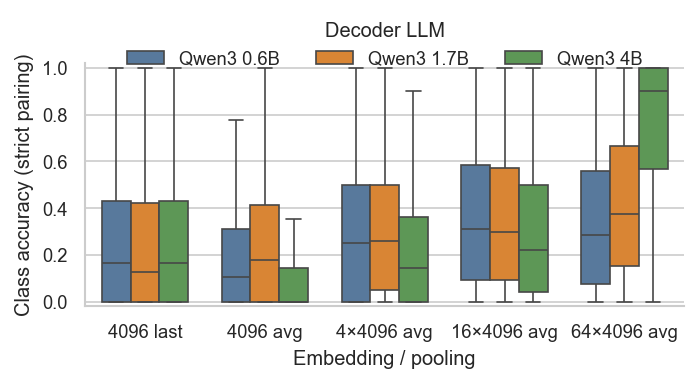

Exported overleaf\graphics\qwen3_repaired_validation_class_accuracy_unordered_boxplot.pdf


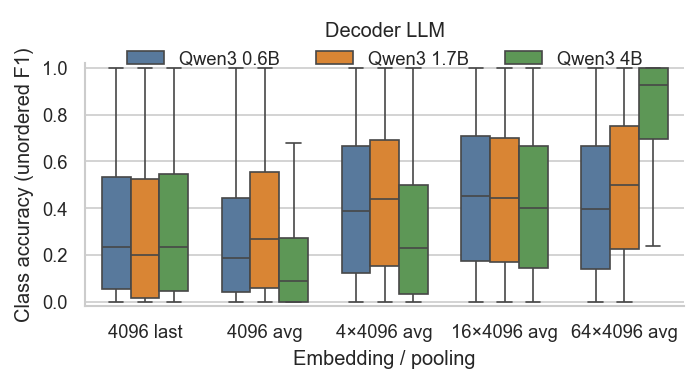

Exported overleaf\graphics\qwen3_repaired_validation_class_accuracy_depth_aware_boxplot.pdf


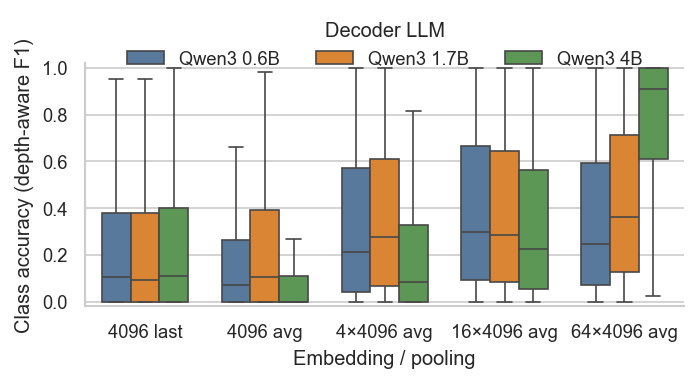

Exported overleaf\graphics\qwen3_repaired_validation_levenshtein_similarity_boxplot.pdf


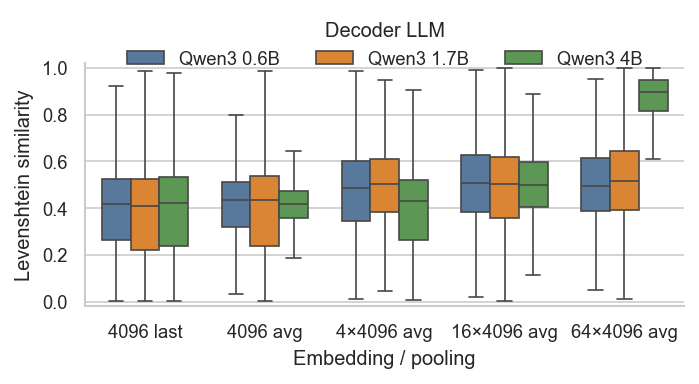

Exported overleaf\graphics\qwen3_repaired_validation_levenshtein_distance_boxplot.pdf


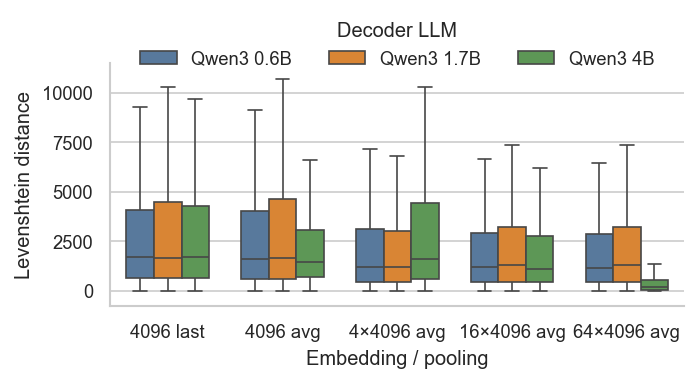

Exported overleaf\graphics\qwen3_repaired_validation_average_bounds_iou_boxplot.pdf


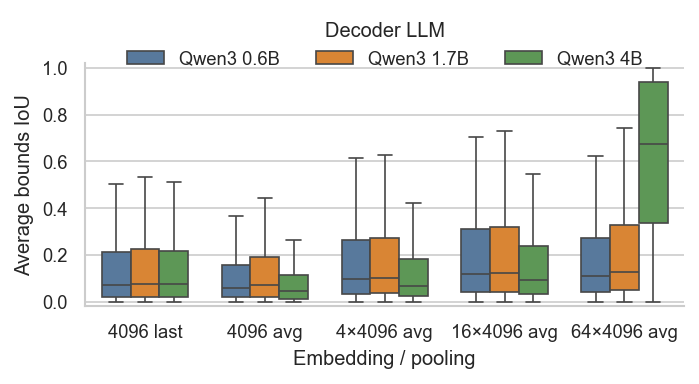

Exported overleaf\graphics\qwen3_repaired_validation_matched_bounds_iou_boxplot.pdf


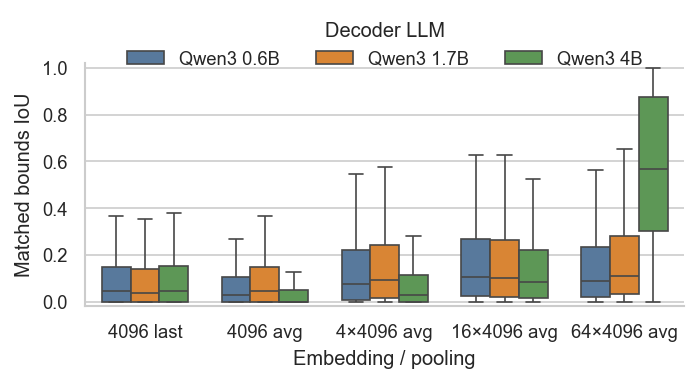


Validation PDF exports:
overleaf\graphics\qwen3_repaired_validation_class_accuracy_boxplot.pdf
overleaf\graphics\qwen3_repaired_validation_class_accuracy_unordered_boxplot.pdf
overleaf\graphics\qwen3_repaired_validation_class_accuracy_depth_aware_boxplot.pdf
overleaf\graphics\qwen3_repaired_validation_levenshtein_similarity_boxplot.pdf
overleaf\graphics\qwen3_repaired_validation_levenshtein_distance_boxplot.pdf
overleaf\graphics\qwen3_repaired_validation_average_bounds_iou_boxplot.pdf
overleaf\graphics\qwen3_repaired_validation_matched_bounds_iou_boxplot.pdf


In [9]:
VALIDATION_Y_PADDING_FRACTION = 0.02

validation_group_counts = validation_plot_data.groupby(
    ["pooling", "model_label"], observed=True
).size()
validation_too_small = validation_group_counts[validation_group_counts.lt(MIN_BOXPLOT_N)]
if not validation_too_small.empty:
    raise ValueError(
        f"Refusing to export validation boxplots with fewer than "
        f"{MIN_BOXPLOT_N} observations:\n{validation_too_small}"
    )


def grouped_validation_boxplot(metric, spec):
    fig, ax = plt.subplots(figsize=FIGSIZE)
    sns.boxplot(
        data=validation_plot_data, x="pooling_label", y=metric, hue="model_label",
        order=[POOL_LABELS[name] for name in POOL_ORDER],
        hue_order=[MODEL_LABELS[size] for size in MODEL_SIZES],
        palette=PALETTE, width=BOX_WIDTH, linewidth=LINE_WIDTH,
        showfliers=SHOW_FLIERS, whis=1.5, ax=ax,
    )
    ax.set_xlabel("Embedding / pooling")
    ax.set_ylabel(spec["label"])

    if spec["ylim"] is not None:
        y_min, y_max = spec["ylim"]
        ax.set_ylim(y_min, y_max)
        y_ticks = ax.get_yticks()
        y_ticks = y_ticks[(y_ticks >= y_min) & (y_ticks <= y_max)]
        y_pad = VALIDATION_Y_PADDING_FRACTION * (y_max - y_min)
        ax.set_ylim(y_min - y_pad, y_max + y_pad)
        ax.set_yticks(y_ticks)
    else:
        y_min, y_max = ax.get_ylim()
        y_pad = VALIDATION_Y_PADDING_FRACTION * (y_max - y_min)
        ax.set_ylim(y_min - y_pad, y_max + y_pad)

    if SHOW_TITLES:
        ax.set_title(f"{spec['label']} — repaired reconstructions, validation only")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="x", visible=False)
    ax.legend(
        title="Decoder LLM", loc="upper center", bbox_to_anchor=(0.5, 1.20),
        ncol=3, frameon=False, borderaxespad=0,
    )
    fig.tight_layout()

    output_path = PDF_DIR / f"{PDF_PREFIX}_validation_{spec['slug']}_boxplot.pdf"
    fig.savefig(
        output_path, format="pdf", bbox_inches="tight",
        metadata={
            "Creator": "Matplotlib + Seaborn",
            "Title": f"{spec['label']} — validation only",
        },
    )
    print(f"Exported {output_path}")
    return fig, ax, output_path


validation_exported_pdfs = []
for metric, spec in METRIC_SPECS.items():
    fig, ax, output_path = grouped_validation_boxplot(metric, spec)
    validation_exported_pdfs.append(output_path)
    plt.show()
    plt.close(fig)

print("\nValidation PDF exports:")
print("\n".join(str(path) for path in validation_exported_pdfs))

## Validation-only LaTeX table

This duplicates the full-corpus table layout using only `validation_descriptive`. It prints the table and exports a standalone `.tex` fragment.

In [10]:
validation_table_stats = validation_descriptive.set_index(
    ["pooling", "model_size_b", "metric"], verify_integrity=True
)

validation_table_header = r"""\begin{table*}[t]
    \centering
    \caption{GUI reconstruction performance on the held-out adapter-validation screens across embedding pooling strategies and decoder LLMs after JSON repair and repetition-loop collapse.
    For each metric, we report the per-screen mean and sample standard deviation (SD).
    Class Accuracy (strict) uses strict component pairing; Class Accuracy (unordered) and Class Accuracy (depth-aware) are the respective F1 scores.}
    \label{tab:gui_reconstruction_validation_results}
    \scriptsize
    \begingroup
    \setlength{\tabcolsep}{2.2pt}
    \renewcommand{\arraystretch}{1.1}
    \resizebox{\linewidth}{!}{%
    \begin{tabular}{@{}ll|*{7}{rr}@{}}
        \toprule
        \textbf{Embedding/Pooling} &
        \textbf{Decoder LLM} &
        \multicolumn{2}{|c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(strict)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(unordered)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(depth-aware)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Levenshtein}\\\textbf{Similarity}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Levenshtein}\\\textbf{Distance}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Average Bounds}\\\textbf{IoU}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Matched Bounds}\\\textbf{IoU}}} \\
        \cmidrule(lr){3-4}
        \cmidrule(lr){5-6}
        \cmidrule(lr){7-8}
        \cmidrule(lr){9-10}
        \cmidrule(lr){11-12}
        \cmidrule(lr){13-14}
        \cmidrule(lr){15-16}
        &
        &
        \multicolumn{1}{|c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} &
        \multicolumn{1}{c}{\textbf{Mean}} &
        \multicolumn{1}{c}{\textbf{SD}} \\
"""

validation_table_rows = []
for pooling in POOL_ORDER:
    validation_table_rows.append(r"        \midrule")
    pooling_tex = pooling.replace("_", r"\_")
    validation_table_rows.append(
        r"        \multirow{" + str(len(MODEL_SIZES))
        + r"}{*}{\texttt{" + pooling_tex + "}}"
    )
    for model_size in MODEL_SIZES:
        validation_table_rows.append(f"            & Qwen3-{model_size:g}B-Base")
        for metric in TABLE_METRICS:
            stats = validation_table_stats.loc[(pooling, model_size, metric)]
            mean, sd = float(stats["mean"]), float(stats["sd"])
            if not all(math.isfinite(value) for value in (mean, sd)):
                raise ValueError(
                    f"Missing validation mean/SD for {pooling}, {model_size}B, {metric}"
                )
            digits = 2 if metric == "levenshtein_distance_repaired" else 4
            validation_table_rows.append(f"            & {mean:.{digits}f} & {sd:.{digits}f}")
        validation_table_rows[-1] += r" \\"

validation_table_footer = r"""        \bottomrule
    \end{tabular}%
    }
    \endgroup
\end{table*}"""

validation_latex_table = (
    validation_table_header
    + "\n".join(validation_table_rows)
    + "\n"
    + validation_table_footer
)
validation_latex_path = PDF_DIR / f"{PDF_PREFIX}_validation_results.tex"
validation_latex_path.write_text(validation_latex_table, encoding="utf-8")
print(validation_latex_table)
print(f"\nExported validation LaTeX table to {validation_latex_path}")

C:\Users\Jonathan\AppData\Local\Temp\ipykernel_28736\3445573253.py:1: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  validation_table_stats = validation_descriptive.set_index(


\begin{table*}[t]
    \centering
    \caption{GUI reconstruction performance on the held-out adapter-validation screens across embedding pooling strategies and decoder LLMs after JSON repair and repetition-loop collapse.
    For each metric, we report the per-screen mean and sample standard deviation (SD).
    Class Accuracy (strict) uses strict component pairing; Class Accuracy (unordered) and Class Accuracy (depth-aware) are the respective F1 scores.}
    \label{tab:gui_reconstruction_validation_results}
    \scriptsize
    \begingroup
    \setlength{\tabcolsep}{2.2pt}
    \renewcommand{\arraystretch}{1.1}
    \resizebox{\linewidth}{!}{%
    \begin{tabular}{@{}ll|*{7}{rr}@{}}
        \toprule
        \textbf{Embedding/Pooling} &
        \textbf{Decoder LLM} &
        \multicolumn{2}{|c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(strict)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Class Accuracy}\\\textbf{(unordered)}}} &
        \multicolumn{2}{c}{\shortstack{\textbf{Class